Index : 230038E

Repo : [https://github.com/NileshAm/EN3160-Image-Processing-and-Machine-Vision](https://github.com/NileshAm/EN3160-Image-Processing-and-Machine-Vision)

# Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import models
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import copy

# Question 1

In [2]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)


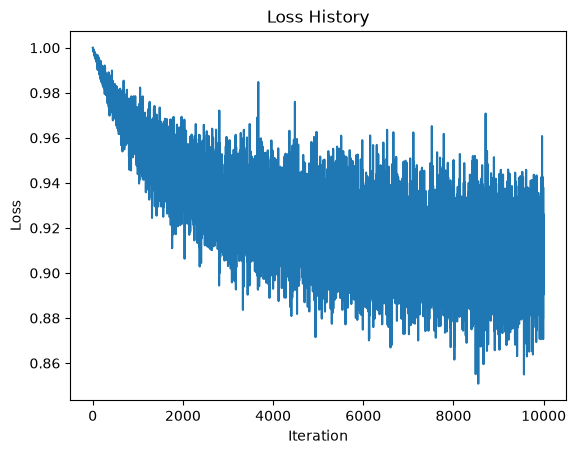

Training accuracy: 31.00%
Test accuracy: 31.05%


In [3]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = torch.randn(Din, K) * std
b = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Convert labels to one-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # Loss calculation (MSE with regularization)
        loss = (
            (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2)
            + reg * torch.sum(w ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)

        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    # if t % 1 == 0:
    #     print(
    #         f"Epoch {t + 1}/{iterations}, "
    #         f"Loss: {running_loss / len(trainloader)}"
    #     )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")


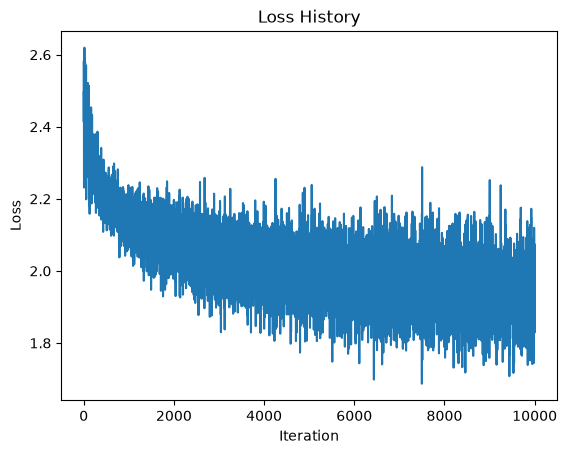

Training accuracy: 34.16%
Test accuracy: 34.25%


In [4]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100            # Hidden layer size
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * (1 / Din**0.5)
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * (1 / H**0.5)
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-3
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Convert labels to one-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_train.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_pred = hidden1.mm(w2) + b2

        # Loss calculation (cross-entropy with regularization)
        loss = (
            nn.functional.cross_entropy(y_pred, labels)
            + reg * torch.sum(w1 ** 2)
            + reg * torch.sum(w2 ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = torch.softmax(y_pred, dim=1)
        dy_pred[torch.arange(Ntr), labels] -= 1
        dy_pred /= Ntr

        dw2 = hidden1.t().mm(dy_pred) + 2 * reg * w2
        db2 = dy_pred.sum(dim=0)

        dhidden = dy_pred.mm(w2.t()) * hidden1 * (1 - hidden1)

        dw1 = x_train.t().mm(dhidden) + 2 * reg * w1
        db1 = dhidden.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    # if t % 1 == 0:
    #     print(
    #         f"Epoch {t + 1}/{iterations}, "
    #         f"Loss: {running_loss / len(trainloader)}"
    #     )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_train.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_train_pred = hidden1.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_test.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_test_pred = hidden1.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")


With the same parameters the model with the hidden layer performs much worse. This is due to much slower learning rate implemented. Increasing the learning rate gave the model same performance as the original model. 

# Question 2

In [5]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

batch_size = 50

trainset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    '0', '1', '2', '3', '4',
    '5', '6', '7', '8', '9'
)


In [6]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    num_correct, num_images = 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        n = labels.size(0)
        running_loss += loss.item() * n
        num_correct += (logits.argmax(dim=1) == labels).sum().item()
        num_images += n
    return running_loss / num_images, 100.0 * num_correct / num_images


@torch.no_grad()
def evaluate(model, loader, criterion, return_confusion=False):
    model.eval()  # disables dropout; batch norm uses running statistics
    running_loss = 0.0
    num_correct, num_images = 0, 0
    cm = np.zeros((10, 10), dtype=np.int64) if return_confusion else None
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        loss = criterion(logits, labels)
        predicted = logits.argmax(dim=1)

        n = labels.size(0)
        running_loss += loss.item() * n
        num_correct += (predicted == labels).sum().item()
        num_images += n
        if return_confusion:
            flat_indices = labels * 10 + predicted
            cm += torch.bincount(flat_indices, minlength=100).view(10, 10).cpu().numpy()

    return running_loss / num_images, 100.0 * num_correct / num_images, cm

In [7]:
def train(model, name):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [], "train_acc": [],
        "test_loss": [], "test_acc": []
    }

    for epoch in range(10):
        tr_loss, tr_acc = train_one_epoch(
            model, trainloader, optimizer, criterion
        )
        te_loss, te_acc, _ = evaluate(
            model, testloader, criterion
        )

        for key, value in zip(history, [tr_loss, tr_acc, te_loss, te_acc]):
            history[key].append(value)

        print(f"{name} | Epoch {epoch+1}/10 | "
                f"Train Acc: {tr_acc:.2f}% | Test Acc: {te_acc:.2f}% | "
                f"Train Loss: {tr_loss:.4f} | Test Loss: {te_loss:.4f}")

    results[name] = history
    _, _, confusions[name] = evaluate(
        model, testloader, criterion, return_confusion=True
    )

    print(f"\n{name} Final Results:")
    print(f"Training Accuracy: {tr_acc:.2f}%")
    print(f"Test Accuracy: {te_acc:.2f}%\n")

    return history, confusions[name]

In [8]:
results = {}
confusions = {}

## LeNet-5

In [9]:
class LeNet5(nn.Module):
    """Classic LeNet-5 layout for 32 x 32 grayscale input."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),     # 32 -> 28
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2),         # 28 -> 14
            nn.Conv2d(6, 16, kernel_size=5),    # 14 -> 10
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2),         # 10 -> 5
            nn.Conv2d(16, 120, kernel_size=5),  # 5 -> 1
            nn.Tanh(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10),                  # logits (no softmax)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [10]:
lenet = LeNet5()
lenet_history, lenet_confusion = train(lenet, "lenet")

lenet | Epoch 1/10 | Train Acc: 93.33% | Test Acc: 97.17% | Train Loss: 0.2293 | Test Loss: 0.0917
lenet | Epoch 2/10 | Train Acc: 97.79% | Test Acc: 97.94% | Train Loss: 0.0704 | Test Loss: 0.0681
lenet | Epoch 3/10 | Train Acc: 98.49% | Test Acc: 98.56% | Train Loss: 0.0482 | Test Loss: 0.0445
lenet | Epoch 4/10 | Train Acc: 98.83% | Test Acc: 98.63% | Train Loss: 0.0374 | Test Loss: 0.0413
lenet | Epoch 5/10 | Train Acc: 99.10% | Test Acc: 98.44% | Train Loss: 0.0291 | Test Loss: 0.0491
lenet | Epoch 6/10 | Train Acc: 99.21% | Test Acc: 98.91% | Train Loss: 0.0243 | Test Loss: 0.0351
lenet | Epoch 7/10 | Train Acc: 99.33% | Test Acc: 98.75% | Train Loss: 0.0214 | Test Loss: 0.0406
lenet | Epoch 8/10 | Train Acc: 99.44% | Test Acc: 98.76% | Train Loss: 0.0169 | Test Loss: 0.0434
lenet | Epoch 9/10 | Train Acc: 99.47% | Test Acc: 99.02% | Train Loss: 0.0157 | Test Loss: 0.0366
lenet | Epoch 10/10 | Train Acc: 99.55% | Test Acc: 98.76% | Train Loss: 0.0138 | Test Loss: 0.0439

lenet Fi

## Modern CNN

In [11]:
class ModernSmallCNN(nn.Module):
    """Exactly three conv layers, each with batch norm and pooling."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 32 -> 16

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 16 -> 8

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 8 -> 4
            nn.Dropout2d(p=0.15),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(p=0.35),
            nn.Linear(64, 10),                    # logits
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [12]:
modern_cnn = ModernSmallCNN()
modern_cnn_history, modern_cnn_confusion = train(modern_cnn, "modern_cnn")

modern_cnn | Epoch 1/10 | Train Acc: 93.34% | Test Acc: 98.56% | Train Loss: 0.2213 | Test Loss: 0.0461
modern_cnn | Epoch 2/10 | Train Acc: 97.46% | Test Acc: 98.83% | Train Loss: 0.0849 | Test Loss: 0.0376
modern_cnn | Epoch 3/10 | Train Acc: 98.01% | Test Acc: 99.00% | Train Loss: 0.0667 | Test Loss: 0.0307
modern_cnn | Epoch 4/10 | Train Acc: 98.38% | Test Acc: 99.02% | Train Loss: 0.0550 | Test Loss: 0.0314
modern_cnn | Epoch 5/10 | Train Acc: 98.53% | Test Acc: 98.83% | Train Loss: 0.0482 | Test Loss: 0.0385
modern_cnn | Epoch 6/10 | Train Acc: 98.67% | Test Acc: 99.15% | Train Loss: 0.0448 | Test Loss: 0.0248
modern_cnn | Epoch 7/10 | Train Acc: 98.81% | Test Acc: 99.18% | Train Loss: 0.0393 | Test Loss: 0.0268
modern_cnn | Epoch 8/10 | Train Acc: 98.92% | Test Acc: 99.28% | Train Loss: 0.0352 | Test Loss: 0.0219
modern_cnn | Epoch 9/10 | Train Acc: 98.99% | Test Acc: 99.20% | Train Loss: 0.0330 | Test Loss: 0.0303
modern_cnn | Epoch 10/10 | Train Acc: 99.11% | Test Acc: 99.32% 

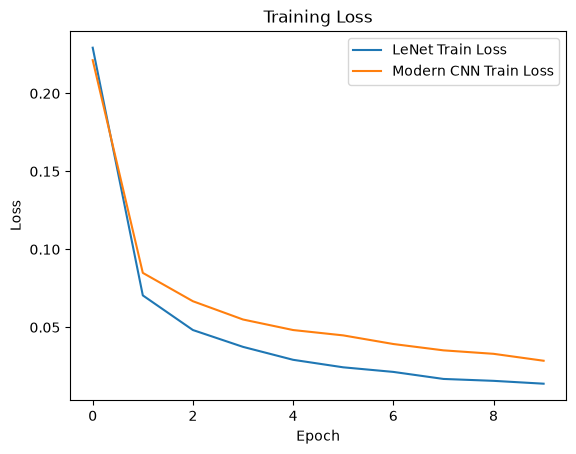

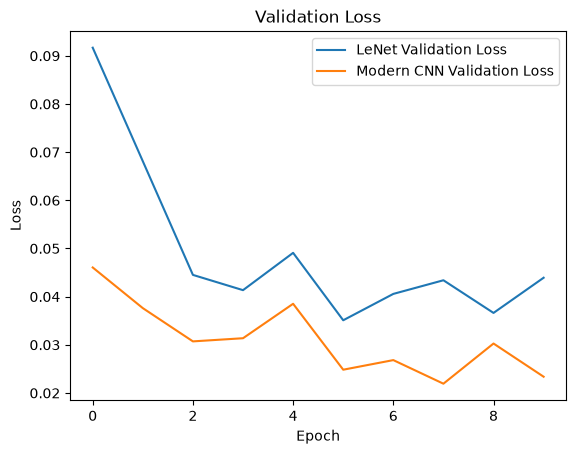

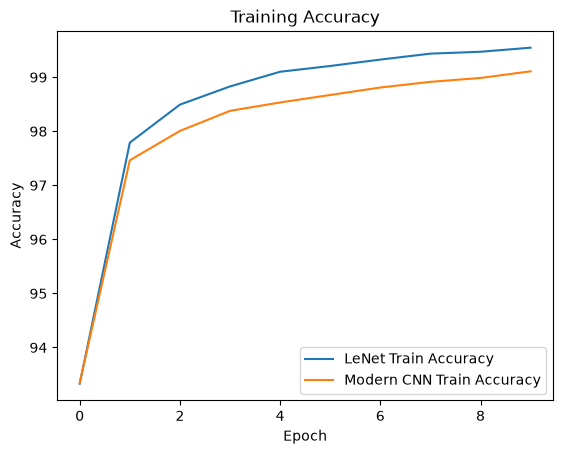

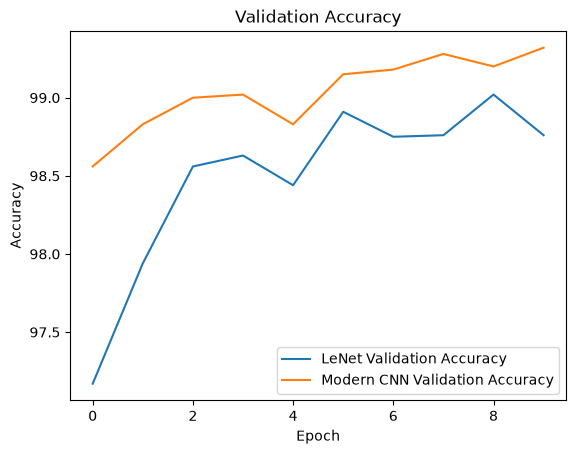

In [13]:
plt.plot(lenet_history["train_loss"], label="LeNet Train Loss")
plt.plot(modern_cnn_history["train_loss"], label="Modern CNN Train Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.show()

plt.plot(lenet_history["test_loss"], label="LeNet Validation Loss")
plt.plot(modern_cnn_history["test_loss"], label="Modern CNN Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss")
plt.legend()
plt.show()

plt.plot(lenet_history["train_acc"], label="LeNet Train Accuracy")
plt.plot(modern_cnn_history["train_acc"], label="Modern CNN Train Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.legend()
plt.show()

plt.plot(lenet_history["test_acc"], label="LeNet Validation Accuracy")
plt.plot(modern_cnn_history["test_acc"], label="Modern CNN Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.show()



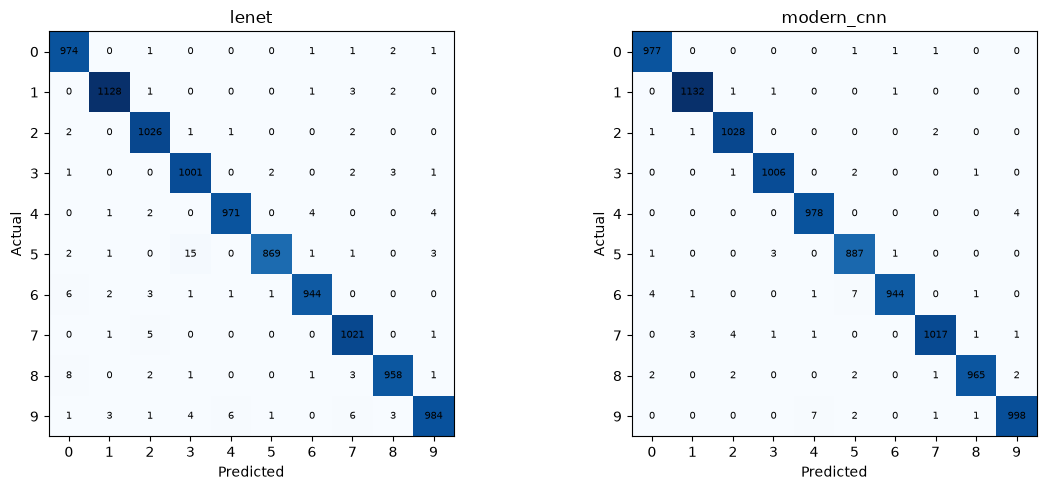

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, cm) in zip(axes, confusions.items()):
    ax.imshow(cm, cmap="Blues")

    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center", fontsize=7)

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

plt.tight_layout()
plt.show()

# Question 3

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])

batch_size = 4

trainset = torchvision.datasets.ImageFolder(
    root="./data/hymenoptera_data/train", transform=train_transform
)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=0
)

valset = torchvision.datasets.ImageFolder(
    root="./data/hymenoptera_data/val", transform=val_transform
)
valloader = torch.utils.data.DataLoader(
    valset, batch_size=batch_size, shuffle=False, num_workers=0
)

classes = trainset.classes
print("Classes:", classes)
print("Training images:", len(trainset))
print("Validation images:", len(valset))
print("Device:", DEVICE)

In [16]:
def train_one_epoch(model, loader, optimizer, criterion, feature_extract=False):
    model.train()
    if feature_extract:
        # Keep the pretrained backbone (including BatchNorm statistics) fixed.
        model.eval()
        model.fc.train()

    running_loss = 0.0
    num_correct, num_images = 0, 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        n = labels.size(0)
        running_loss += loss.item() * n
        num_correct += (logits.argmax(dim=1) == labels).sum().item()
        num_images += n

    return running_loss / num_images, 100.0 * num_correct / num_images


@torch.no_grad()
def evaluate(model, loader, criterion, return_confusion=False):
    model.eval()
    running_loss = 0.0
    num_correct, num_images = 0, 0
    cm = np.zeros((2, 2), dtype=np.int64) if return_confusion else None

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        logits = model(images)
        loss = criterion(logits, labels)
        predicted = logits.argmax(dim=1)

        n = labels.size(0)
        running_loss += loss.item() * n
        num_correct += (predicted == labels).sum().item()
        num_images += n

        if return_confusion:
            indices = labels * 2 + predicted
            cm += torch.bincount(indices, minlength=4).view(2, 2).cpu().numpy()

    return running_loss / num_images, 100.0 * num_correct / num_images, cm

def train_model(model, optimizer, scheduler, name, feature_extract=False):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc = -1.0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(iterations):
        tr_loss, tr_acc = train_one_epoch(
            model, trainloader, optimizer, criterion, feature_extract
        )
        val_loss, val_acc, _ = evaluate(model, valloader, criterion)

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())

        scheduler.step()
        print(f"{name} | Epoch {epoch+1}/{iterations} | "
              f"Train Acc: {tr_acc:.2f}% | Val Acc: {val_acc:.2f}% | "
              f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}")

    model.load_state_dict(best_weights)
    return history, best_acc


In [17]:
# Common settings for both models
criterion = nn.CrossEntropyLoss()
iterations = 25
lr = 0.001

## Fine tuning

In [ ]:
# (a) Fine-tuning: update all layers
model_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model_ft.fc = nn.Linear(model_ft.fc.in_features, 2)
model_ft = model_ft.to(DEVICE)

optimizer_ft = torch.optim.SGD(model_ft.parameters(), lr=lr, momentum=0.9)
scheduler_ft = torch.optim.lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

history_ft, best_acc_ft = train_model(
    model_ft, optimizer_ft, scheduler_ft, "Fine-tuning"
)


## As feature extractor

In [ ]:
# (b) Feature extraction: train only the final layer
model_fe = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_fe.parameters():
    param.requires_grad = False
model_fe.fc = nn.Linear(model_fe.fc.in_features, 2)
model_fe = model_fe.to(DEVICE)

optimizer_fe = torch.optim.SGD(model_fe.fc.parameters(), lr=lr, momentum=0.9)
scheduler_fe = torch.optim.lr_scheduler.StepLR(optimizer_fe, step_size=7, gamma=0.1)

history_fe, best_acc_fe = train_model(
    model_fe, optimizer_fe, scheduler_fe, "Feature extraction", feature_extract=True
)


## Evaluation

In [20]:
# Evaluate the best checkpoint of each model on the validation set
results = {
    "Fine-tuning": {"model": model_ft, "history": history_ft, "best_val_acc": best_acc_ft},
    "Feature extraction": {"model": model_fe, "history": history_fe, "best_val_acc": best_acc_fe}
}
confusions = {}

print(f"{'Model':<22} {'Final Train':>12} {'Final Val':>12} {'Best Val':>12}")
for name, result in results.items():
    model = result["model"]
    h = result["history"]
    val_loss, val_acc, cm = evaluate(model, valloader, criterion, return_confusion=True)
    confusions[name] = cm
    print(f"{name:<22} {h['train_acc'][-1]:>11.2f}% "
          f"{h['val_acc'][-1]:>11.2f}% {val_acc:>11.2f}%")

# Final Train/Val = epoch 25; Best Val = best checkpoint re-evaluated.


Model                   Final Train    Final Val     Best Val
Fine-tuning                  88.11%       88.89%       92.16%
Feature extraction           97.95%       95.42%       96.08%


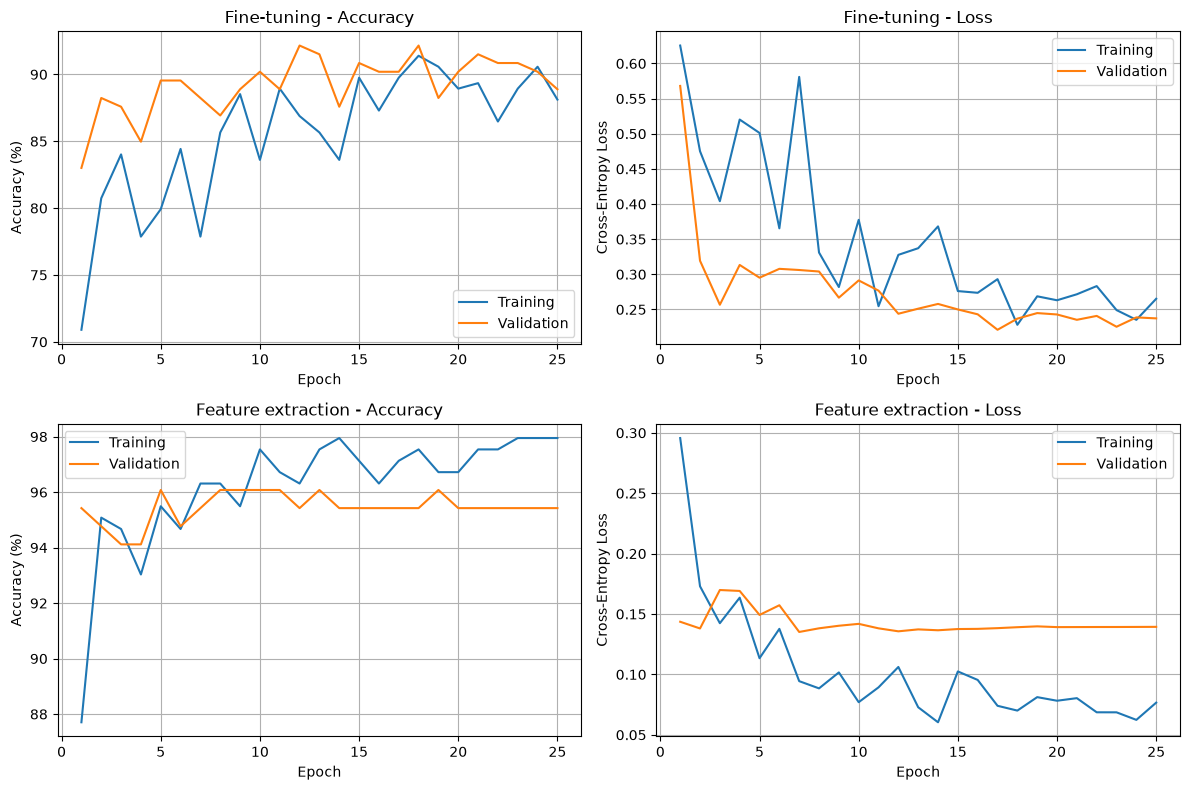

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, (name, result) in enumerate(results.items()):
    h = result["history"]
    epochs = range(1, iterations + 1)

    axes[i, 0].plot(epochs, h["train_acc"], label="Training")
    axes[i, 0].plot(epochs, h["val_acc"], label="Validation")
    axes[i, 0].set_title(f"{name} - Accuracy")
    axes[i, 0].set_ylabel("Accuracy (%)")
    axes[i, 0].legend()

    axes[i, 1].plot(epochs, h["train_loss"], label="Training")
    axes[i, 1].plot(epochs, h["val_loss"], label="Validation")
    axes[i, 1].set_title(f"{name} - Loss")
    axes[i, 1].set_ylabel("Cross-Entropy Loss")
    axes[i, 1].legend()

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.grid(True)

plt.tight_layout()
plt.show()

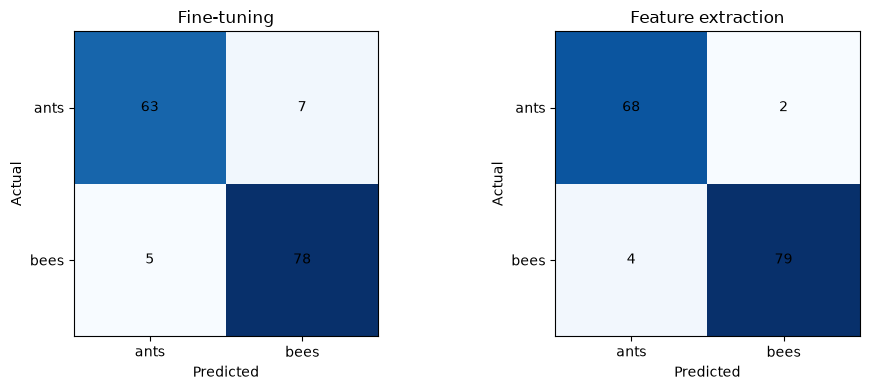

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, cm) in zip(axes, confusions.items()):
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks(range(2), classes)
    ax.set_yticks(range(2), classes)

plt.tight_layout()
plt.show()

Using the `ResNet18` as an feature extractor give better accuracy than fine tuning the model for the same set of hyperparameter. `ResNet18` is already trained with a better dataset than the small `Hymenoptera` dataset, so freezing the CNN layer and only training the bottom most layer for accuracy is much effective than training the whole model from scratch